# Chapitre 14 - Cours 3 : cartes auto-organisatrices, ACP et ses extensions, ACI, MDS

Ce notebook couvre les sections 14.4 à 14.8 du livre : des méthodes qui cherchent une
**structure de petite dimension** (une variété, des sources cachées, une carte du plan)
rendant compte de données de grande dimension.

1. cartes auto-organisatrices de Kohonen (SOM, figures 14.15 à 14.18) ;
2. analyse en composantes principales (figures 14.20 à 14.24) ;
3. analyse de Procrustes et formes moyennes (figures 14.25, 14.26) ;
4. courbes principales (figure 14.27) ;
5. clustering spectral et ACP à noyau (figures 14.29, 14.30) ;
6. ACP parcimonieuse et factorisation en matrices positives (présentation) ;
7. analyse factorielle et analyse en composantes indépendantes (figures 14.37, 14.38) ;
8. positionnement multidimensionnel (MDS, figure 14.43).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch14_non_supervise as ns
set_style()

## 1. Cartes auto-organisatrices (section 14.4)

### 1.1 Principe

Une carte auto-organisatrice (*self-organizing map*, SOM) est une version **contrainte** des
K-means : les $K = q_1 q_2$ prototypes $m_j \in \mathbb{R}^p$ sont indexés par les nœuds
$\ell_j \in \{1..q_1\} \times \{1..q_2\}$ d'une grille du plan, et l'on veut que des nœuds voisins
sur la grille aient des prototypes proches dans $\mathbb{R}^p$. Image : des « boutons » cousus
régulièrement sur un tissu (initialement le plan des deux premières composantes principales),
que l'on déforme pour approcher au mieux les données.

**Algorithme (version en ligne).** Les observations sont traitées une par une. Pour $x_i$ :

1. on trouve le prototype le plus proche $m_j$ (distance euclidienne dans $\mathbb{R}^p$) ;
2. on déplace vers $x_i$ ce prototype **et ses voisins sur la grille** :
   $$m_k \leftarrow m_k + \alpha\,(x_i - m_k) \quad \text{pour tout } k \text{ tel que }
   \|\ell_j - \ell_k\| < r \qquad (14.46).$$

Le taux d'apprentissage $\alpha$ décroît (par exemple de 1 à 0) et le rayon $r$ de $R$ à 1 au fil
des itérations. Une variante pondère la mise à jour par $h(\|\ell_j - \ell_k\|)$, décroissante
de la distance sur la grille (14.47).

> **Intuition.** La distance qui définit le voisinage se mesure **sur la grille**, pas dans
> $\mathbb{R}^p$ : c'est ce qui force la carte à rester « lisse ». Si $r$ est si petit qu'un
> voisinage ne contient que le prototype gagnant, la SOM devient une version en ligne des
> K-means.

### 1.2 Données sur une demi-sphère (figure 14.15)

On simule 90 points en dimension 3, en trois groupes de 30 situés près de $(0,0,1)$ (groupe
rouge, le plus resserré en angle), $(1,0,0)$ et $(0,1,0)$, avec un bruit gaussien
d'écart-type 0,6 sur chaque coordonnée (détails dans l'exercice 14.5).

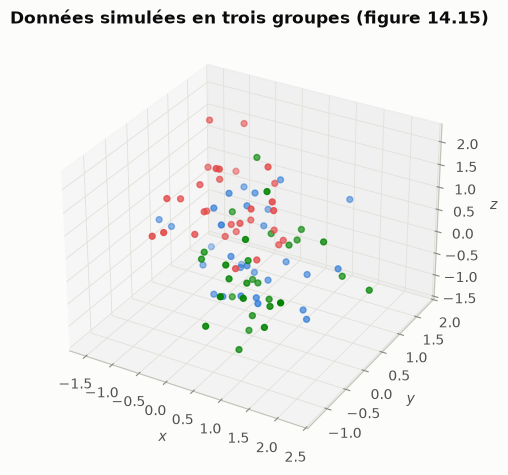

In [2]:
Xs, ys = ns.donnees_demi_sphere(rng=np.random.RandomState(0))
coul_s = np.array([COLORS[7], COLORS[5], COLORS[0]])[ys]
fig = plt.figure(figsize=(7, 5.5))
ax = fig.add_subplot(projection="3d")
ax.scatter(*Xs.T, c=coul_s, s=18)
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_zlabel("$z$")
ax.set_title("Données simulées en trois groupes (figure 14.15)")
plt.show()

On ajuste une grille $5 \times 5$ avec un rayon initial $R = 2$ (environ un tiers des prototypes
dans chaque voisinage), 40 passages sur les 90 observations (3600 itérations), $\alpha$ et $r$
décroissant linéairement.

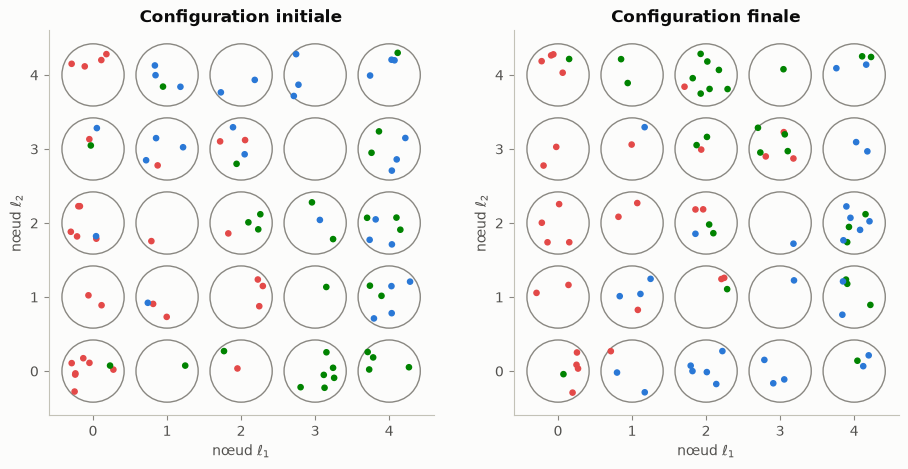

In [3]:
som0 = ns.init_som_acp(Xs, 5, 5)
res_som = ns.som(Xs, 5, 5, n_iter=3600, R=2.0, rng=np.random.RandomState(0), suivi=45)
lab_init = ns.distances_carrees(Xs, som0).argmin(1)


def dessiner_carte(ax, labels, grille, titre, rng):
    for (a, b) in grille:
        ax.add_patch(plt.Circle((a, b), 0.42, fill=False, color=GRAY))
    jit = rng.uniform(-0.3, 0.3, size=(len(labels), 2))
    pos = grille[labels] + jit
    ax.scatter(*pos.T, c=coul_s, s=14)
    ax.set_xlim(-0.6, 4.6)
    ax.set_ylim(-0.6, 4.6)
    ax.set_aspect("equal")
    ax.set_title(titre)
    ax.set_xlabel("nœud $\\ell_1$")
    ax.set_ylabel("nœud $\\ell_2$")
    ax.grid(False)


fig, axes = plt.subplots(1, 2, figsize=(11, 5))
r_jit = np.random.RandomState(1)
dessiner_carte(axes[0], lab_init, res_som["grille"], "Configuration initiale", r_jit)
dessiner_carte(axes[1], res_som["labels"], res_som["grille"], "Configuration finale", r_jit)
plt.show()

Chaque cercle est un prototype ; les points qui s'y projettent sont dessinés au hasard dans le
cercle (figure 14.16). Au départ (plan principal), les groupes se mélangent ; à la fin, ils
occupent des régions distinctes de la carte.

Représentons la carte ajustée dans $\mathbb{R}^3$ : les prototypes et les arêtes de la grille
(figure 14.17).

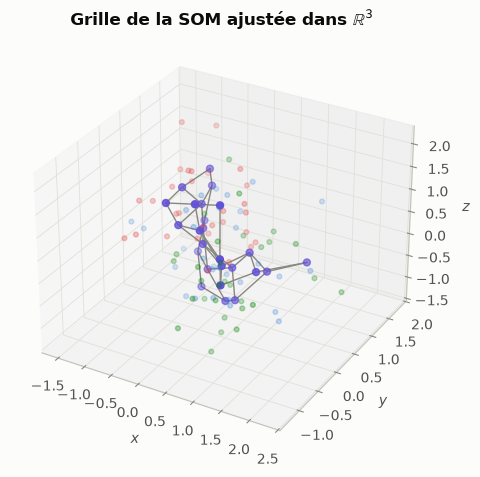

In [4]:
M = res_som["prototypes"].reshape(5, 5, 3)
fig = plt.figure(figsize=(7, 5.5))
ax = fig.add_subplot(projection="3d")
ax.scatter(*Xs.T, c=coul_s, s=12, alpha=0.6)
for a in range(5):
    ax.plot(*M[a, :, :].T, color=GRAY, lw=1)
    ax.plot(*M[:, a, :].T, color=GRAY, lw=1)
ax.scatter(*res_som["prototypes"].T, color=COLORS[6], s=25)
ax.set_xlabel("$x$")
ax.set_ylabel("$y$")
ax.set_zlabel("$z$")
ax.set_title("Grille de la SOM ajustée dans $\\mathbb{R}^3$")
plt.show()

### 1.3 Erreur de reconstruction (figure 14.18)

Pour juger si la contrainte de la carte est raisonnable, on compare l'erreur de
reconstruction $\sum_i \|x_i - m_{j(i)}\|^2$ ($m_{j(i)}$ : prototype le plus proche) à celle des
K-means avec 25 centres, nécessairement plus petite. On ajoute la **version batch** de la SOM
(éq. (14.48)) : chaque prototype devient la moyenne des observations affectées à ses voisins
sur la grille ; quand le voisinage se réduit au seul gagnant, c'est exactement une itération des
K-means.

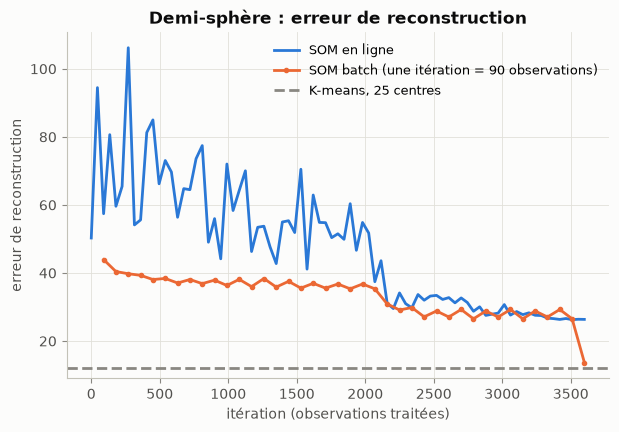

In [5]:
km25 = ns.kmeans(Xs, 25, n_init=10, rng=np.random.RandomState(0))
res_batch = ns.som_batch(Xs, 5, 5, n_iter=40, R=2.0, r_final=1.0)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(res_som["historique"][:, 0], res_som["historique"][:, 1], color=BLUE,
        label="SOM en ligne")
ax.plot(np.arange(1, 41) * 90, res_batch["historique"], "o-", ms=3, color=ORANGE,
        label="SOM batch (une itération = 90 observations)")
ax.axhline(km25[2], color=GRAY, ls="--", label="K-means, 25 centres")
ax.set_xlabel("itération (observations traitées)")
ax.set_ylabel("erreur de reconstruction")
ax.set_title("Demi-sphère : erreur de reconstruction")
ax.legend()
plt.show()

In [6]:
print("Erreur finale : SOM en ligne %.1f, SOM batch %.1f, K-means %.1f"
      % (res_som["erreur"], res_batch["erreur"], km25[2]))

Erreur finale : SOM en ligne 26.4, SOM batch 13.6, K-means 12.1


La SOM fait fortement baisser l'erreur. Avec le schéma en ligne (α décroissant linéairement
jusqu'à 0), les prototypes restent toutefois éloignés des moyennes de leurs cellules ; la
version batch, dont le voisinage final se réduit au gagnant, atteint presque le niveau des
K-means, signe que la contrainte bidimensionnelle est raisonnable ici.

> **À retenir.** Une SOM est un K-means dont les centres sont attachés aux nœuds d'une grille et
> mis à jour avec leurs voisins. Elle fournit une **carte** bidimensionnelle des données, mais
> les distances sur la carte ne reflètent pas les distances dans $\mathbb{R}^p$.

## 2. Composantes principales (section 14.5.1)

### 2.1 Meilleure approximation linéaire de rang $q$

On cherche le sous-espace affine de dimension $q$ qui approche au mieux les données :
$f(\lambda) = \mu + \mathbf{V}_q \lambda$ (14.49), où $\mathbf{V}_q$ est une matrice $p \times q$ à
colonnes orthonormées et $\lambda \in \mathbb{R}^q$. On minimise

$$\min_{\mu, \{\lambda_i\}, \mathbf{V}_q} \sum_{i=1}^N \|x_i - \mu - \mathbf{V}_q \lambda_i\|^2
\qquad (14.50).$$

On montre (exercice 14.7) que $\hat\mu = \bar x$ et $\hat\lambda_i = \mathbf{V}_q^T(x_i - \bar x)$
(14.51)-(14.52), puis qu'il reste à minimiser $\sum_i \|(x_i - \bar x) - \mathbf{V}_q\mathbf{V}_q^T
(x_i - \bar x)\|^2$ (14.53) : $\mathbf{V}_q\mathbf{V}_q^T$ est le projecteur orthogonal sur le
sous-espace. Avec la décomposition en valeurs singulières de la matrice centrée
$\mathbf{X} = \mathbf{U}\mathbf{D}\mathbf{V}^T$ (14.54), la solution est formée des $q$ premières
colonnes de $\mathbf{V}$, et les $\hat\lambda_i$ sont les lignes de $\mathbf{U}_q\mathbf{D}_q$, les
**composantes principales**.

### 2.2 Plan principal de la demi-sphère (figure 14.21)

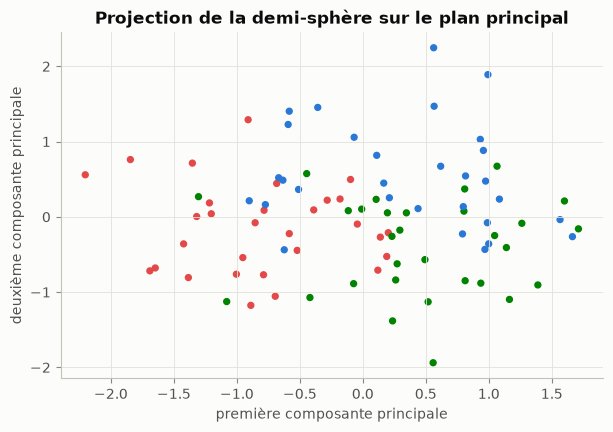

In [7]:
pca_s = ns.acp(Xs, 2)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(*pca_s["scores"].T, c=coul_s, s=18)
ax.set_xlabel("première composante principale")
ax.set_ylabel("deuxième composante principale")
ax.set_title("Projection de la demi-sphère sur le plan principal")
plt.show()

La projection linéaire sépare déjà assez bien les groupes ; c'est elle qui a servi à
initialiser la SOM. La part de variance expliquée par les deux premières composantes est :

In [8]:
d = pca_s["d"]
print("Part de variance expliquée : %.1f %%" % (100 * (d[:2] ** 2).sum() / (d ** 2).sum()))

Part de variance expliquée : 81.1 %


### 2.3 Chiffres manuscrits : les « 3 » (figures 14.22 à 14.24)

On considère les 658 images $16 \times 16$ de chiffres « 3 » de l'échantillon d'apprentissage,
vues comme des points de $\mathbb{R}^{256}$.

Images de 3 : (658, 256)


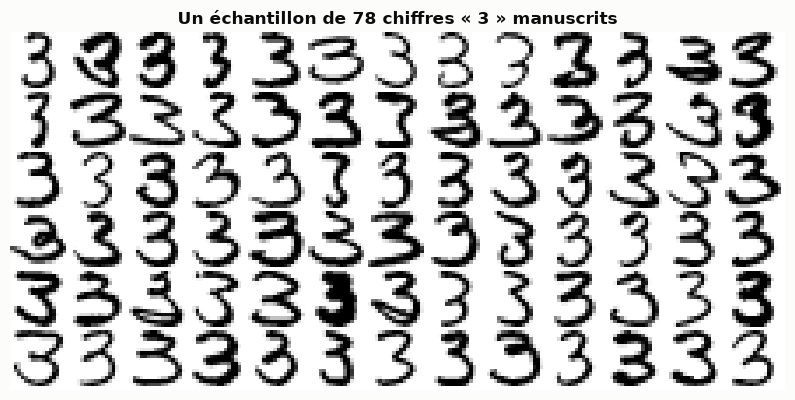

In [9]:
Xz, yz = datasets.load_zip("train")
X3 = Xz[yz == 3]
print("Images de 3 :", X3.shape)


def montrer_images(ax, images, n_lignes, n_cols, titre):
    mosaique = np.ones((n_lignes * 17, n_cols * 17)) * -1
    for k, im in enumerate(images[: n_lignes * n_cols]):
        a, b = divmod(k, n_cols)
        mosaique[a * 17:a * 17 + 16, b * 17:b * 17 + 16] = im.reshape(16, 16)
    ax.imshow(-mosaique, cmap="gray")
    ax.set_title(titre)
    ax.axis("off")


fig, ax = plt.subplots(figsize=(10, 5))
montrer_images(ax, X3[np.random.RandomState(0).permutation(len(X3))], 6, 13,
               "Un échantillon de 78 chiffres « 3 » manuscrits")
plt.show()

Les deux premières composantes principales, avec la grille formée par les quantiles 5 %, 25 %,
50 %, 75 % et 95 % de chaque composante ; on entoure l'image la plus proche de chaque sommet
(dans le plan principal) et on affiche ces images à droite.

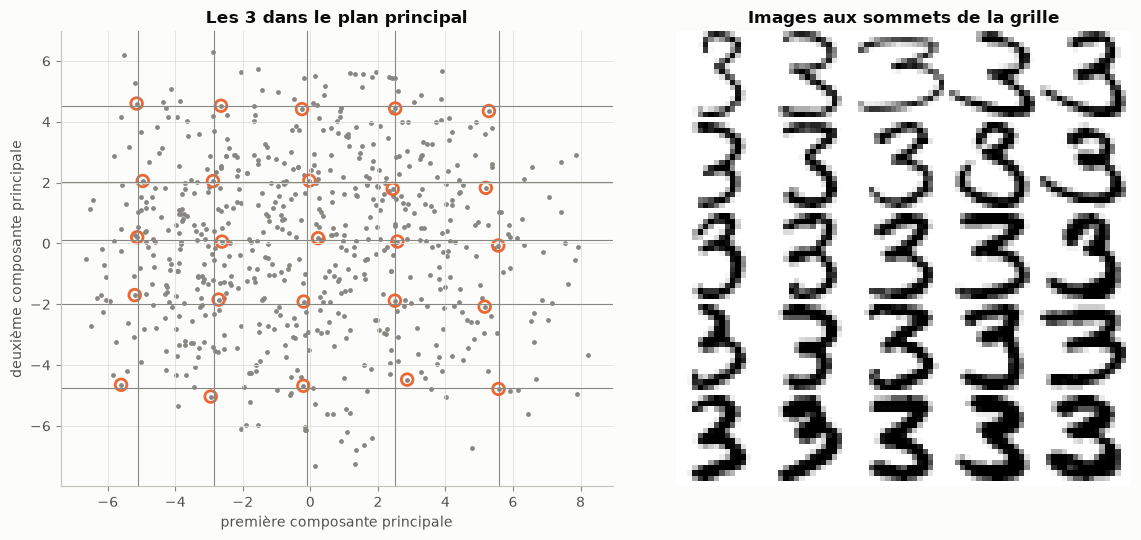

In [10]:
pca3 = ns.acp(X3, 2)
S3 = pca3["scores"]
q1 = np.quantile(S3[:, 0], [0.05, 0.25, 0.5, 0.75, 0.95])
q2 = np.quantile(S3[:, 1], [0.05, 0.25, 0.5, 0.75, 0.95])
choisis = np.zeros((5, 5), int)
for a in range(5):
    for b in range(5):
        choisis[a, b] = ((S3 - [q1[a], q2[b]]) ** 2).sum(1).argmin()

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
axes[0].scatter(*S3.T, s=6, color=GRAY)
for v in q1:
    axes[0].axvline(v, color=GRAY, lw=0.8)
for v in q2:
    axes[0].axhline(v, color=GRAY, lw=0.8)
axes[0].scatter(*S3[choisis.ravel()].T, s=70, facecolor="none", edgecolor=ORANGE, lw=2)
axes[0].set_xlabel("première composante principale")
axes[0].set_ylabel("deuxième composante principale")
axes[0].set_title("Les 3 dans le plan principal")
mos = np.ones((5 * 17, 5 * 17)) * -1
for a in range(5):
    for b in range(5):
        mos[(4 - b) * 17:(4 - b) * 17 + 16, a * 17:a * 17 + 16] = X3[choisis[a, b]].reshape(16, 16)
axes[1].imshow(-mos, cmap="gray")
axes[1].set_title("Images aux sommets de la grille")
axes[1].axis("off")
plt.tight_layout()
plt.show()

Le déplacement horizontal (1re composante) correspond surtout à l'allongement de la queue du 3,
le déplacement vertical (2e composante) plutôt à l'épaisseur du trait. Le modèle à deux
composantes s'écrit $\hat f(\lambda) = \bar x + \lambda_1 v_1 + \lambda_2 v_2$ (14.55) ; affichons
$\bar x$, $v_1$ et $v_2$ comme des images.

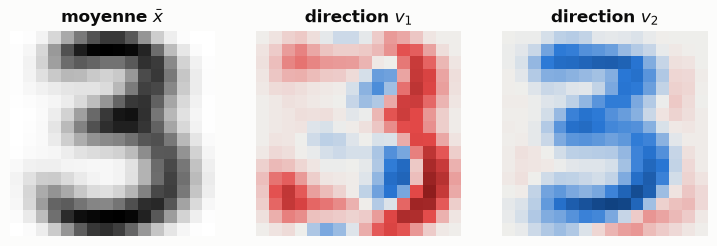

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3.2))
for ax, im, titre in ((axes[0], pca3["moyenne"], "moyenne $\\bar x$"),
                      (axes[1], pca3["V"][:, 0], "direction $v_1$"),
                      (axes[2], pca3["V"][:, 1], "direction $v_2$")):
    lim = np.abs(im).max()
    ax.imshow(im.reshape(16, 16), cmap=DIV if ax is not axes[0] else "gray_r",
              vmin=-lim if ax is not axes[0] else None, vmax=lim if ax is not axes[0] else None)
    ax.set_title(titre)
    ax.axis("off")
plt.show()

Figure 14.24 : les 256 valeurs singulières, comparées à celles de données où chaque colonne
(pixel) a été permutée au hasard, ce qui détruit les corrélations entre pixels.

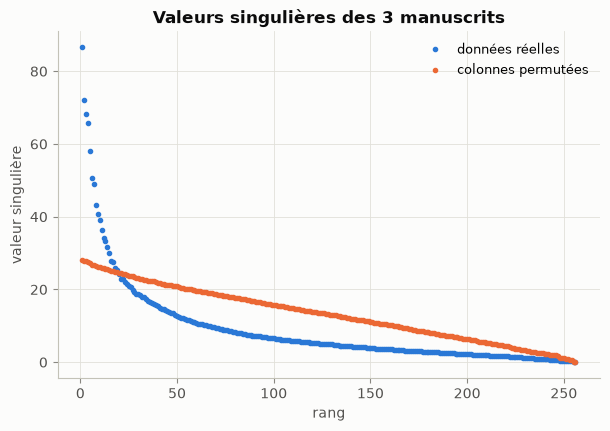

In [12]:
rng = np.random.RandomState(0)
X3_perm = np.column_stack([rng.permutation(X3[:, j]) for j in range(256)])
d_perm = ns.acp(X3_perm, 1)["d"]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(np.arange(1, 257), pca3["d"], "o", ms=3, color=BLUE, label="données réelles")
ax.plot(np.arange(1, 257), d_perm, "o", ms=3, color=ORANGE, label="colonnes permutées")
ax.set_xlabel("rang")
ax.set_ylabel("valeur singulière")
ax.set_title("Valeurs singulières des 3 manuscrits")
ax.legend()
plt.show()

In [13]:
part = np.cumsum(pca3["d"] ** 2) / (pca3["d"] ** 2).sum()
print("Composantes nécessaires pour 63 %% de la variance : %d ; pour 90 %% : %d"
      % (np.searchsorted(part, 0.63) + 1, np.searchsorted(part, 0.90) + 1))

Composantes nécessaires pour 63 % de la variance : 12 ; pour 90 % : 52


Les pixels étant très corrélés, quelques dizaines de composantes résument l'essentiel de la
variabilité (environ 12 pour 63 % et 50 pour 90 %, comme dans le livre).

## 3. Procrustes et formes moyennes

### 3.1 Le problème de Procrustes

Deux ensembles de $N$ points repères **appariés** dans $\mathbb{R}^p$, matrices $\mathbf{X}_1$
et $\mathbf{X}_2$ ($N \times p$), représentent la même forme (par exemple deux « S » manuscrits).
On cherche la translation $\mu$ et la matrice orthogonale $\mathbf{R}$ qui superposent au mieux
$\mathbf{X}_1$ sur $\mathbf{X}_2$ :

$$\min_{\mu, \mathbf{R}} \|\mathbf{X}_2 - (\mathbf{X}_1\mathbf{R} + \mathbf{1}\mu^T)\|_F
\qquad (14.56),$$

où $\|\mathbf{A}\|_F^2 = \operatorname{tr}(\mathbf{A}^T\mathbf{A})$ est la norme de Frobenius.

Avec $\tilde{\mathbf{X}}_1, \tilde{\mathbf{X}}_2$ les matrices centrées et la SVD
$\tilde{\mathbf{X}}_1^T\tilde{\mathbf{X}}_2 = \mathbf{U}\mathbf{D}\mathbf{V}^T$, la solution est
$\hat{\mathbf{R}} = \mathbf{U}\mathbf{V}^T$ et la translation aligne les centres de gravité
(14.57) ; avec un facteur d'échelle $\beta > 0$ (14.58), $\hat\beta = \operatorname{tr}(\mathbf{D})
/ \|\tilde{\mathbf{X}}_1\|_F^2$ (démonstrations dans l'exercice 14.8).

Les « S » de la signature du livre ne sont pas disponibles : nous fabriquons des « S » de 96
points repères, légèrement déformés, puis tournés et translatés (figure 14.25).

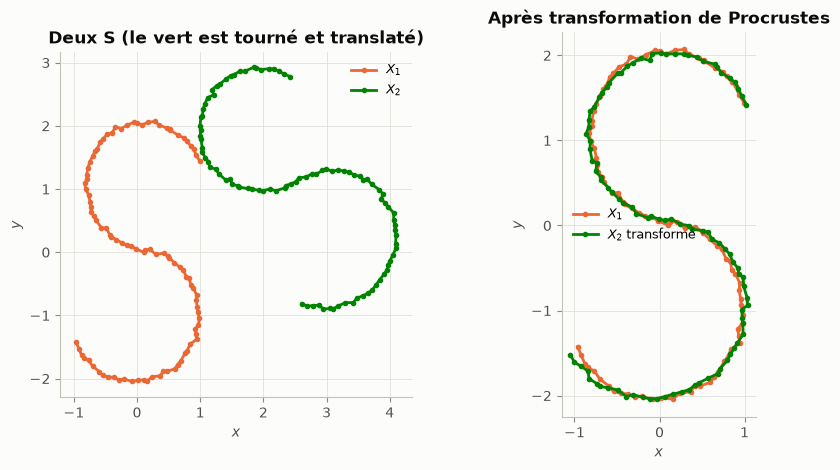

In [14]:
rng = np.random.RandomState(0)
S1 = ns.forme_s(rng=rng, deformation=0.06, bruit=0.02)
S2 = ns.forme_s(rng=rng, deformation=0.06, bruit=0.02) @ ns.rotation2d(0.6) + [2.5, 1.0]
proc = ns.procrustes(S2, S1)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, B, titre in ((axes[0], S2, "Deux S (le vert est tourné et translaté)"),
                     (axes[1], proc["ajuste"], "Après transformation de Procrustes")):
    ax.plot(*S1.T, "o-", ms=3, color=ORANGE, label="$X_1$")
    ax.plot(*B.T, "o-", ms=3, color=COLORS[5], label="$X_2$ transformé" if ax is axes[1] else "$X_2$")
    ax.set_aspect("equal")
    ax.set_title(titre)
    ax.set_xlabel("$x$")
    ax.set_ylabel("$y$")
    ax.legend()
plt.show()

In [15]:
print("Angle de la rotation estimée : %.3f rad (rotation appliquée : 0,6 rad ; l'écart vient "
      "des petites déformations propres à chaque S)"
      % np.arctan2(proc["R"][1, 0], proc["R"][0, 0]))
print("Distance de Procrustes : %.3f" % proc["distance"])

Angle de la rotation estimée : 0.661 rad (rotation appliquée : 0,6 rad ; l'écart vient des petites déformations propres à chaque S)
Distance de Procrustes : 0.529


### 3.2 Moyenne de Procrustes de plusieurs formes (figure 14.26)

Pour $L$ formes, on cherche la forme $\mathbf{M}$ la plus proche, en distance de Procrustes
moyenne, de toutes les formes :
$\min_{\{\mathbf{R}_\ell\}, \mathbf{M}} \sum_{\ell} \|\mathbf{X}_\ell\mathbf{R}_\ell - \mathbf{M}\|_F^2$
(14.59). Algorithme alterné : (1) $\mathbf{M}$ fixée, on résout $L$ problèmes de Procrustes ;
(2) on remplace $\mathbf{M}$ par la moyenne des formes alignées. Le critère décroît à chaque étape.

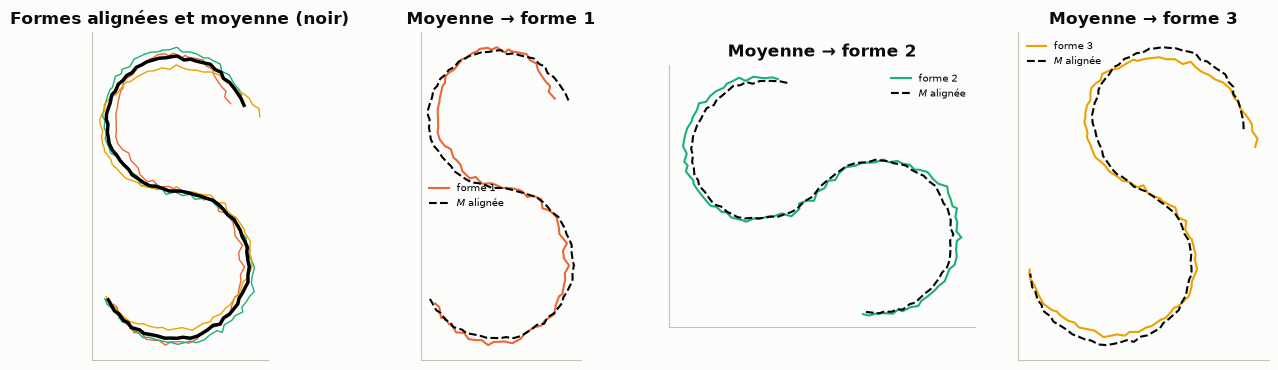

In [16]:
formes = [ns.forme_s(rng=rng, deformation=0.15, bruit=0.02) @ ns.rotation2d(a) + c
          for a, c in ((0.0, [0, 0]), (0.8, [3, 1]), (-0.5, [-2, 2]))]
moy = ns.moyenne_procrustes(formes)
fig, axes = plt.subplots(1, 4, figsize=(13, 3.8))
for l, A in enumerate(moy["alignees"]):
    axes[0].plot(*A.T, "-", color=COLORS[l + 1], lw=1)
axes[0].plot(*moy["M"].T, "-", color="k", lw=2.5)
axes[0].set_title("Formes alignées et moyenne (noir)")
for l in range(3):
    pr = ns.procrustes(moy["M"], formes[l])
    axes[l + 1].plot(*formes[l].T, "-", color=COLORS[l + 1], lw=1.5, label="forme %d" % (l + 1))
    axes[l + 1].plot(*pr["ajuste"].T, "--", color="k", lw=1.5, label="$M$ alignée")
    axes[l + 1].set_title("Moyenne → forme %d" % (l + 1))
    axes[l + 1].legend(fontsize=7)
for ax in axes:
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

La moyenne n'est définie qu'à une rotation près. Le problème le plus général, la **moyenne
invariante affine** (14.60), remplace les rotations par des matrices inversibles quelconques
; elle se calcule sans itération à partir des projecteurs $\mathbf{H}_\ell =
\mathbf{X}_\ell(\mathbf{X}_\ell^T\mathbf{X}_\ell)^{-1}\mathbf{X}_\ell^T$ (exercices 14.9 et 14.10).

## 4. Courbes principales (section 14.5.2)

Une **courbe principale** généralise la droite principale. Soit $f(\lambda)$ une courbe
paramétrée de $\mathbb{R}^p$ et $\lambda_f(x)$ le paramètre du point de la courbe le plus proche de
$x$. La courbe est **principale** si elle est **auto-consistante** :

$$f(\lambda) = \mathbb{E}\big(X \mid \lambda_f(X) = \lambda\big) \qquad (14.61),$$

chaque point de la courbe est la moyenne des points qui s'y projettent.

**Algorithme (14.62).** Partant de la première composante principale, on alterne :

(a) $\hat f_j(\lambda) \leftarrow \mathbb{E}(X_j \mid \lambda(X) = \lambda)$ pour chaque
    coordonnée $j$, estimé par un **lisseur** (ici une régression locale linéaire) de $X_j$ en
    fonction de l'abscisse curviligne $\lambda$ ;

(b) $\hat\lambda_f(x) \leftarrow \operatorname{argmin}_{\lambda'} \|x - \hat f(\lambda')\|^2$ :
    projection de chaque point sur la courbe.

> **Remarque.** Avec un lisseur **linéaire** (moindres carrés), la procédure converge vers la
> première composante principale : c'est la méthode de la puissance itérée.

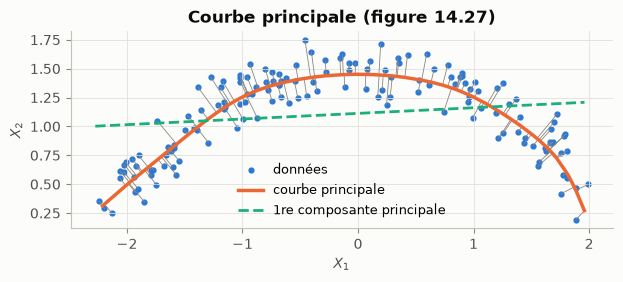

In [17]:
rng = np.random.RandomState(0)
tt = rng.uniform(0.1 * np.pi, 0.95 * np.pi, 150)
Xpc = np.column_stack([2 * np.cos(tt), 1.5 * np.sin(tt)]) + 0.15 * rng.normal(size=(150, 2))
cp = ns.courbe_principale(Xpc, h=0.08)
lam, proj = ns.projeter_sur_polyligne(Xpc, cp["courbe"])
droite = ns.acp(Xpc, 1)

fig, ax = plt.subplots(figsize=(7, 5))
for i in range(len(Xpc)):
    ax.plot([Xpc[i, 0], proj[i, 0]], [Xpc[i, 1], proj[i, 1]], color=GRAY, lw=0.6)
ax.scatter(*Xpc.T, s=12, color=BLUE, label="données")
ax.plot(*cp["courbe"].T, color=ORANGE, lw=2.5, label="courbe principale")
o = np.argsort(droite["scores"][:, 0])
ax.plot(*droite["reconstruction"][o].T, "--", color=COLORS[2], label="1re composante principale")
ax.set_aspect("equal")
ax.set_xlabel("$X_1$")
ax.set_ylabel("$X_2$")
ax.set_title("Courbe principale (figure 14.27)")
ax.legend()
plt.show()

In [18]:
print("Somme des carrés des distances : droite principale %.2f, courbe principale %.2f"
      % (((Xpc - droite["reconstruction"]) ** 2).sum(), cp["distances"][-1]))

Somme des carrés des distances : droite principale 19.50, courbe principale 2.54


Les **surfaces principales** (dimension 2) se définissent de même avec des lisseurs de
surface ; avec un lisseur à noyau, on retrouve la forme de la SOM batch (14.48), mais avec un
prototype par observation. Les **points principaux** (les $k$ points minimisant l'erreur
quadratique moyenne de quantification) sont l'analogue théorique des centres des K-means.

## 5. Clustering spectral (section 14.5.3)

### 5.1 Graphe de similarité et laplacien

Les K-means utilisent une métrique sphérique : ils échouent sur des groupes **non convexes**
comme des cercles concentriques. On représente plutôt les observations comme les sommets d'un
**graphe** pondéré : $w_{ii'} = s_{ii'} = e^{-\|x_i - x_{i'}\|^2/c}$ si $i'$ est parmi les $k$ plus
proches voisins de $i$ (ou l'inverse), $w_{ii'} = 0$ sinon. Le **degré** du sommet $i$ est
$g_i = \sum_{i'} w_{ii'}$, et le **laplacien** du graphe est

$$\mathbf{L} = \mathbf{G} - \mathbf{W}, \qquad \mathbf{G} = \operatorname{diag}(g_1, \dots, g_N)
\qquad (14.63).$$

**Propriété clé.** Pour tout vecteur $f \in \mathbb{R}^N$,

$$f^T\mathbf{L}f = \sum_i g_i f_i^2 - \sum_{i,i'} f_i f_{i'} w_{ii'}
  = \frac12 \sum_{i,i'} w_{ii'}(f_i - f_{i'})^2 \qquad (14.64).$$

*Preuve.* On développe $\frac12\sum_{i,i'} w_{ii'}(f_i^2 - 2 f_i f_{i'} + f_{i'}^2)$ ; par symétrie de
$\mathbf{W}$, $\frac12\sum_{i,i'} w_{ii'}f_i^2 = \frac12\sum_i g_i f_i^2$ et de même pour le terme
en $f_{i'}^2$. $\square$

Donc $\mathbf{L}$ est symétrique positive, $\mathbf{L}\mathbf{1} = 0$, et $f^T\mathbf{L}f$ est petit
quand $f$ varie peu le long des arêtes de fort poids. Si le graphe a $m$ composantes connexes,
les indicatrices de ces composantes engendrent le noyau de $\mathbf{L}$ (exercice 14.21).

**Clustering spectral.** On calcule les vecteurs propres associés aux $m$ plus petites valeurs
propres de $\mathbf{L}$ (en ignorant le vecteur constant), on les range en colonnes d'une matrice
$\mathbf{Z}$ ($N \times m$), puis on applique les K-means aux **lignes** de $\mathbf{Z}$.

### 5.2 Trois cercles concentriques (figure 14.29)

450 points uniformément répartis en angle sur trois cercles de rayons 1 ; 2,8 et 5, avec un
bruit gaussien d'écart-type 0,25 ; graphe des 10 plus proches voisins, $c = 2$.

In [19]:
Xc, yc = ns.donnees_cercles(rng=np.random.RandomState(0))
spec = ns.clustering_spectral(Xc, 3, c=2.0, k_voisins=10, rng=np.random.RandomState(0))
km_c = ns.kmeans(Xc, 3, rng=np.random.RandomState(0))[0]
print("Rand ajusté : spectral %.3f, K-means %.3f"
      % (ns.indice_rand_ajuste(spec["labels"], yc), ns.indice_rand_ajuste(km_c, yc)))

Rand ajusté : spectral 1.000, K-means 0.004


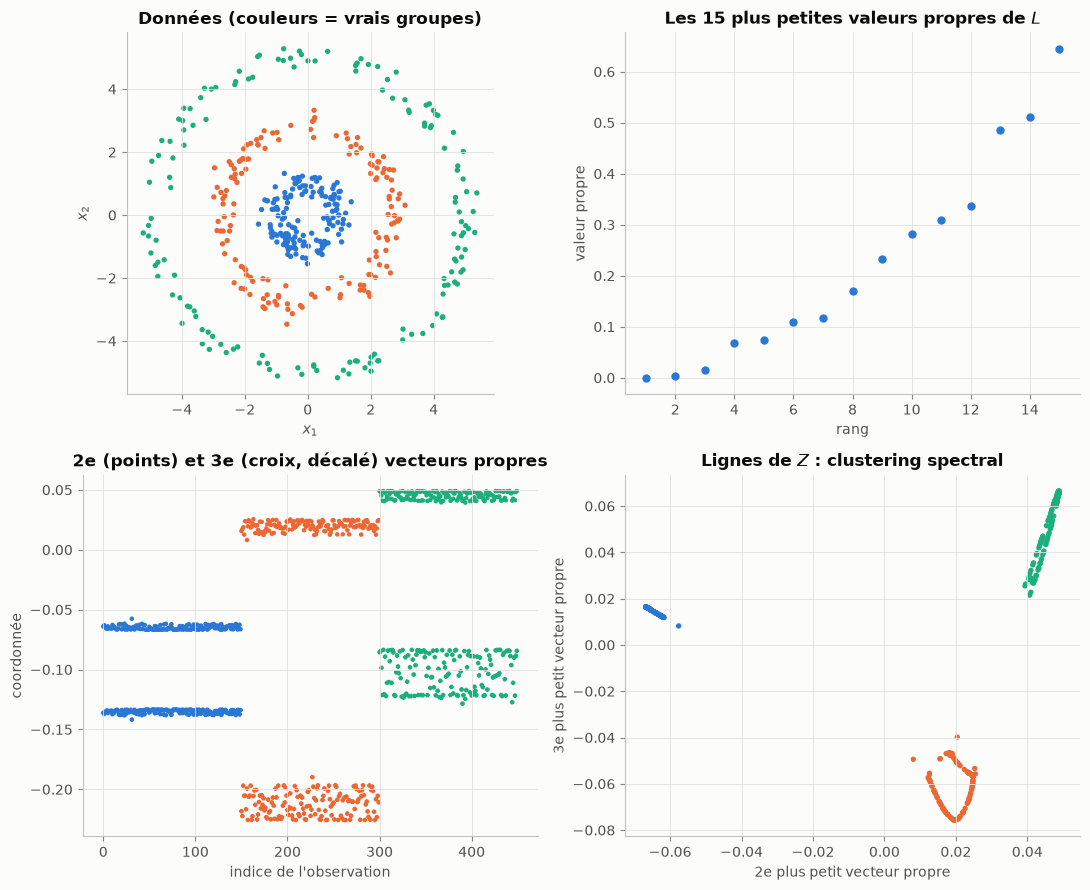

In [20]:
coul_c = np.array(COLORS[:3])[yc]
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
axes[0, 0].scatter(*Xc.T, c=coul_c, s=8)
axes[0, 0].set_aspect("equal")
axes[0, 0].set_title("Données (couleurs = vrais groupes)")
axes[0, 0].set_xlabel("$x_1$")
axes[0, 0].set_ylabel("$x_2$")
axes[0, 1].plot(np.arange(1, 16), spec["valeurs_propres"][:15], "o", color=BLUE)
axes[0, 1].set_title("Les 15 plus petites valeurs propres de $L$")
axes[0, 1].set_xlabel("rang")
axes[0, 1].set_ylabel("valeur propre")
axes[1, 0].scatter(np.arange(450), spec["vecteurs"][:, 1], c=coul_c, s=5)
axes[1, 0].scatter(np.arange(450), spec["vecteurs"][:, 2] - 0.15, c=coul_c, s=5, marker="x")
axes[1, 0].set_title("2e (points) et 3e (croix, décalé) vecteurs propres")
axes[1, 0].set_xlabel("indice de l'observation")
axes[1, 0].set_ylabel("coordonnée")
axes[1, 1].scatter(spec["vecteurs"][:, 1], spec["vecteurs"][:, 2], c=coul_c, s=8)
axes[1, 1].set_title("Lignes de $Z$ : clustering spectral")
axes[1, 1].set_xlabel("2e plus petit vecteur propre")
axes[1, 1].set_ylabel("3e plus petit vecteur propre")
plt.tight_layout()
plt.show()

Dans les coordonnées spectrales, les trois cercles deviennent trois paquets compacts que les
K-means séparent sans difficulté, alors que les K-means directs échouent.

## 6. ACP à noyau (section 14.5.4)

L'ACP ne dépend des données qu'à travers la matrice de Gram $\mathbf{K} = \mathbf{X}\mathbf{X}^T$ :
avec $\mathbf{M} = \mathbf{1}\mathbf{1}^T/N$, le double centrage
$\tilde{\mathbf{K}} = (\mathbf{I} - \mathbf{M})\mathbf{K}(\mathbf{I} - \mathbf{M}) = \mathbf{U}\mathbf{D}^2
\mathbf{U}^T$ (14.65) donne les composantes $\mathbf{Z} = \mathbf{U}\mathbf{D}$. En effet
$\tilde{\mathbf{K}} = \tilde{\mathbf{X}}\tilde{\mathbf{X}}^T$ avec $\tilde{\mathbf{X}} = \mathbf{U}\mathbf{D}\mathbf{V}^T$
(SVD de la matrice centrée), d'où $\tilde{\mathbf{K}} = \mathbf{U}\mathbf{D}^2\mathbf{U}^T$.

L'**ACP à noyau** remplace $\mathbf{K}$ par une matrice de noyau $K(x_i, x_{i'})$, interprétée
comme les produits scalaires de transformations non linéaires implicites $\phi(x_i)$, par exemple
le noyau radial $K(x, x') = e^{-\|x - x'\|^2/c}$ (14.67).

> **Lien avec le clustering spectral.** Les vecteurs propres de plus grandes valeurs propres
> de $\tilde{\mathbf{K}}$ sont ceux de plus petites valeurs propres de $\mathbf{I} - \tilde{\mathbf{K}}$
> (14.68), matrice proche du laplacien : les différences sont le centrage et la diagonale des
> degrés. Figure 14.30 : comparons quatre variantes sur les cercles.

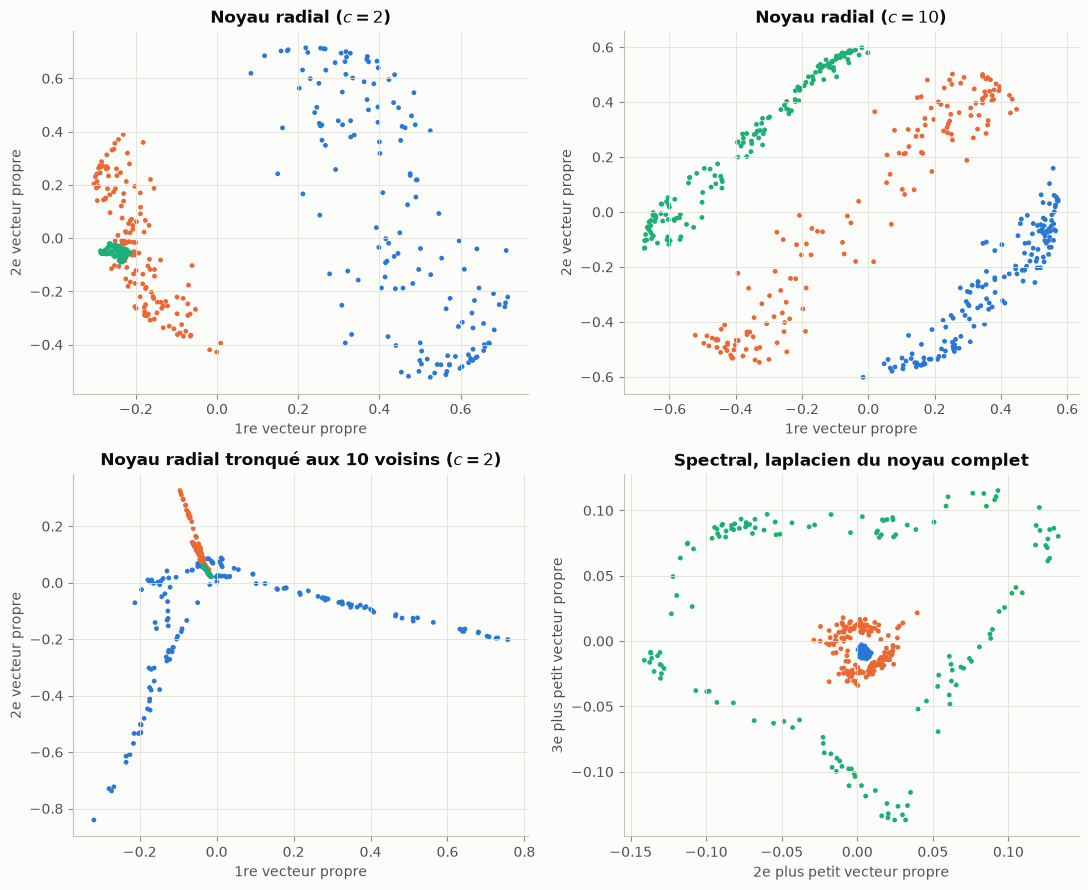

In [21]:
K2 = ns.noyau_gaussien(Xc, c=2.0)
K10 = ns.noyau_gaussien(Xc, c=10.0)
Wnn = ns.matrice_adjacence(Xc, 2.0, k_voisins=10)
kp2 = ns.acp_noyau(K2, 2)["Z"]
kp10 = ns.acp_noyau(K10, 2)["Z"]
kpnn = ns.acp_noyau(Wnn, 2)["Z"]
vals_full, vecs_full = np.linalg.eigh(ns.laplacien(ns.matrice_adjacence(Xc, 2.0)))

fig, axes = plt.subplots(2, 2, figsize=(11, 9))
panneaux = [(kp2, "Noyau radial ($c=2$)", "1re", "2e"),
            (kp10, "Noyau radial ($c=10$)", "1re", "2e"),
            (kpnn, "Noyau radial tronqué aux 10 voisins ($c=2$)", "1re", "2e"),
            (vecs_full[:, 1:3], "Spectral, laplacien du noyau complet", "2e plus petit",
             "3e plus petit")]
for ax, (Z_, titre, a, b) in zip(axes.ravel(), panneaux):
    ax.scatter(Z_[:, 0], Z_[:, 1], c=coul_c, s=6)
    ax.set_title(titre)
    ax.set_xlabel("%s vecteur propre" % a)
    ax.set_ylabel("%s vecteur propre" % b)
plt.tight_layout()
plt.show()

L'ACP à noyau est très sensible à l'échelle $c$ et à la nature du noyau ; la troncature aux
plus proches voisins est essentielle au succès du clustering spectral (le laplacien du noyau
complet ne sépare pas les cercles).

## 7. ACP parcimonieuse (section 14.5.5) - présentation

On interprète une composante principale par ses **coefficients** (*loadings*) $v_j$ ; c'est plus
facile s'ils sont pour la plupart nuls. Zou, Hastie et Tibshirani partent de la propriété de
reconstruction de l'ACP et minimisent, pour $K$ composantes,

$$\sum_{i=1}^N \|x_i - \Theta\mathbf{V}^Tx_i\|_2^2 + \lambda\sum_{k=1}^K \|v_k\|_2^2
  + \sum_{k=1}^K \lambda_{1k}\|v_k\|_1 \quad \text{sous } \Theta^T\Theta = \mathbf{I}_K
  \qquad (14.71).$$

À $\Theta$ fixé, ce sont $K$ régressions **elastic net** ; à $\mathbf{V}$ fixé, un problème de
Procrustes réduit résolu par une SVD (exercice 14.12). Illustration sur des données où
seules 4 des 10 variables portent la première direction de variance.

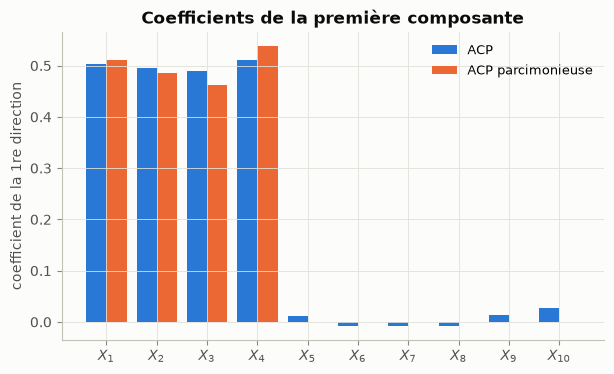

In [22]:
rng = np.random.RandomState(0)
facteur = rng.normal(size=(200, 1))
Xsp = 0.6 * rng.normal(size=(200, 10))
Xsp[:, :4] += 1.5 * facteur
v_acp = ns.acp(Xsp, 1)["V"][:, 0]
sp = ns.acp_parcimonieuse(Xsp, 1, lam2=1.0, lam1=150.0)
v_sp = sp["directions"][:, 0] * np.sign(sp["directions"][0, 0])
v_acp = v_acp * np.sign(v_acp[0])
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(np.arange(10) - 0.2, v_acp, width=0.4, color=BLUE, label="ACP")
ax.bar(np.arange(10) + 0.2, v_sp, width=0.4, color=ORANGE, label="ACP parcimonieuse")
ax.set_xticks(range(10))
ax.set_xticklabels(["$X_{%d}$" % (j + 1) for j in range(10)])
ax.set_ylabel("coefficient de la 1re direction")
ax.set_title("Coefficients de la première composante")
ax.legend()
plt.show()

La direction parcimonieuse annule exactement les coefficients des variables de bruit, alors
que ceux de l'ACP ordinaire sont petits mais non nuls.

## 8. Factorisation en matrices positives (section 14.6) - présentation

Pour des données **positives** (images, comptages), on approche la matrice $N \times p$
$\mathbf{X} \approx \mathbf{W}\mathbf{H}$ (14.72) avec $\mathbf{W}$ ($N \times r$) et $\mathbf{H}$
($r \times p$) **à coefficients positifs**. On maximise la log-vraisemblance d'un modèle où
$x_{ij}$ suit une loi de Poisson de moyenne $(\mathbf{W}\mathbf{H})_{ij}$ :

$$L(\mathbf{W}, \mathbf{H}) = \sum_{i,j}\big[x_{ij}\log(\mathbf{W}\mathbf{H})_{ij} -
(\mathbf{W}\mathbf{H})_{ij}\big] \qquad (14.73),$$

par les mises à jour multiplicatives de Lee et Seung (14.74), qui préservent la positivité et
font croître $L$ (exercices 14.23 et 14.24, traités dans un autre notebook) :

$$w_{ik} \leftarrow w_{ik}\frac{\sum_j h_{kj}x_{ij}/(\mathbf{W}\mathbf{H})_{ij}}{\sum_j h_{kj}},
\qquad h_{kj} \leftarrow h_{kj}\frac{\sum_i w_{ik}x_{ij}/(\mathbf{W}\mathbf{H})_{ij}}{\sum_i w_{ik}}.$$

In [ ]:
X3pos = (X3 + 1) / 2          # niveaux de gris ramenés dans [0, 1]
Wn, Hn, histo_nmf = ns.nmf(X3pos, 16, n_iter=300, rng=np.random.RandomState(0))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].plot(histo_nmf, color=BLUE)
axes[0].set_xlabel("itération")
axes[0].set_ylabel("log-vraisemblance $L(W, H)$")
axes[0].set_title("Croissance de (14.73)")
mos = np.zeros((2 * 17, 8 * 17))
for k in range(16):
    a, b = divmod(k, 8)
    mos[a * 17:a * 17 + 16, b * 17:b * 17 + 16] = Hn[k].reshape(16, 16) / Hn[k].max()
axes[1].imshow(mos, cmap="gray_r")
axes[1].set_title("Les 16 images de base (lignes de $H$)")
axes[1].axis("off")
plt.tight_layout()
plt.show()

Contrairement aux directions de l'ACP (qui mêlent coefficients positifs et négatifs), les
images de base de la NMF sont des **morceaux** de chiffres (arcs, traits) qui s'additionnent.
La solution n'est en général pas unique. L'**analyse archétypale** (section 14.6.1) impose en
plus que les prototypes soient des combinaisons convexes des données.